# Phase 4 — Model Explainability, Probability Calibration, and Revenue at Risk

This phase extends the selected churn model from Phase 3 from customer ranking into decision support.

The analysis evaluates whether predicted churn probabilities are well calibrated, explains the behavioral drivers of churn risk, and combines customer churn probability with historical customer value to estimate revenue at risk.

The Phase 3 model specification remains fixed. Phase 4 does not use the final test period to select a new predictive model.

### 4.1 Environment Setup

Phase 4 reuses the fixed five-feature Logistic Regression specification selected in Phase 3.

The notebook independently reconstructs the historical customer snapshots and model inputs so that the calibration and revenue-risk analysis can be reproduced without relying on variables stored in another notebook.

In [2]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sqlalchemy import create_engine, text
from dotenv import load_dotenv

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
)
from sklearn.calibration import calibration_curve


# Locate the project root and load environment variables.
PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")


# PostgreSQL connection.
DATABASE_URL = (
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:"
    f"{os.getenv('DB_PASSWORD')}@"
    f"{os.getenv('DB_HOST')}:"
    f"{os.getenv('DB_PORT')}/"
    f"{os.getenv('DB_NAME')}"
)

engine = create_engine(DATABASE_URL)

print("Phase 4 environment ready.")

Phase 4 environment ready.


### 4.2 Reconstruct the Fixed Phase 3 Customer Snapshots

Phase 4 reuses the exact leakage-safe snapshot definition from Phase 3.

Each snapshot contains five predictive features calculated from the 180 days before the cutoff:

- recency;
- purchase frequency;
- monetary value;
- total units purchased;
- average order value.

The following 90 days are used only to determine the churn label.

In [3]:
def build_customer_snapshot(cutoff_date, engine):
    """
    Build a leakage-safe customer snapshot.

    Features use the 180 days before the cutoff.
    Churn is determined from the 90 days after the cutoff.
    """

    cutoff_date = pd.Timestamp(cutoff_date)
    observation_start = cutoff_date - pd.Timedelta(days=180)
    label_end = cutoff_date + pd.Timedelta(days=90)

    query = """
    WITH observation AS (
        SELECT
            customer_id,
            MAX(invoice_date) AS last_purchase_date,
            COUNT(DISTINCT invoice) AS frequency,
            SUM(line_revenue) AS monetary_value,
            SUM(quantity) AS total_units,
            SUM(line_revenue) / COUNT(DISTINCT invoice) AS avg_order_value
        FROM retail_transactions
        WHERE invoice_date >= :observation_start
          AND invoice_date < :cutoff_date
        GROUP BY customer_id
    ),

    future_purchases AS (
        SELECT DISTINCT customer_id
        FROM retail_transactions
        WHERE invoice_date >= :cutoff_date
          AND invoice_date < :label_end
    )

    SELECT
        o.customer_id,
        CAST(:cutoff_date AS timestamp) AS cutoff_date,

        CAST(:cutoff_date AS date)
            - CAST(o.last_purchase_date AS date) AS recency_days,

        o.frequency,
        ROUND(o.monetary_value, 2) AS monetary_value,
        o.total_units,
        ROUND(o.avg_order_value, 2) AS avg_order_value,

        CASE
            WHEN f.customer_id IS NULL THEN 1
            ELSE 0
        END AS churn

    FROM observation o

    LEFT JOIN future_purchases f
        ON o.customer_id = f.customer_id

    ORDER BY o.customer_id;
    """

    params = {
        "observation_start": observation_start,
        "cutoff_date": cutoff_date,
        "label_end": label_end,
    }

    with engine.connect() as connection:
        snapshot = pd.read_sql(
            text(query),
            connection,
            params=params,
        )

    return snapshot

#### 4.2.1 Regenerate Historical Snapshots

The original historical cutoff dates are regenerated using the fixed Phase 3 snapshot function.

Matching the Phase 3 row counts and churn rates provides a reproducibility check before model reconstruction and calibration.

In [4]:
cutoff_dates = [
    "2010-09-01",
    "2010-12-01",
    "2011-03-01",
    "2011-06-01",
    "2011-09-01",
]

snapshots = {}

for cutoff in cutoff_dates:
    snapshots[cutoff] = build_customer_snapshot(
        cutoff,
        engine,
    )


snapshot_summary = pd.DataFrame(
    [
        {
            "cutoff_date": cutoff,
            "customers": len(snapshot),
            "non_churn": int((snapshot["churn"] == 0).sum()),
            "churn": int((snapshot["churn"] == 1).sum()),
            "churn_rate_pct": snapshot["churn"].mean() * 100,
        }
        for cutoff, snapshot in snapshots.items()
    ]
)

snapshot_summary["churn_rate_pct"] = (
    snapshot_summary["churn_rate_pct"].round(2)
)

snapshot_summary

,cutoff_date,customers,non_churn,churn,churn_rate_pct
0,2010-09-01,2822,1750,1072,37.99
1,2010-12-01,3465,1318,2147,61.96
2,2011-03-01,3338,1414,1924,57.64
3,2011-06-01,2658,1328,1330,50.04
4,2011-09-01,2768,1680,1088,39.31


#### Snapshot Reproduction Check

All five historical snapshots reproduce the Phase 3 customer counts and churn rates exactly.

This confirms that Phase 4 is using the same observation windows, churn definition, customer eligibility rules, and transaction data as the original modeling workflow.

### 4.3 Reconstruct the Fixed Phase 3 Final Model

The selected Phase 3 model is reconstructed without changing its specification.

The four development snapshots are combined, the same four skewed purchasing variables are log-transformed, and standardization parameters are learned from the development data only.

The 2011-09-01 snapshot remains outside model fitting and is used for the later-period probability evaluation.

In [5]:
feature_columns = [
    "recency_days",
    "frequency",
    "monetary_value",
    "total_units",
    "avg_order_value",
]

log_features = [
    "frequency",
    "monetary_value",
    "total_units",
    "avg_order_value",
]


# Four development periods used for the final Phase 3 refit.
development_snapshot = pd.concat(
    [
        snapshots["2010-09-01"],
        snapshots["2010-12-01"],
        snapshots["2011-03-01"],
        snapshots["2011-06-01"],
    ],
    ignore_index=True,
)

test_snapshot = snapshots["2011-09-01"].copy()


X_development = development_snapshot[feature_columns].copy()
y_development = development_snapshot["churn"].copy()

X_test = test_snapshot[feature_columns].copy()
y_test = test_snapshot["churn"].copy()


# Convert database numeric values to standard numeric dtypes.
for column in feature_columns:
    X_development[column] = pd.to_numeric(
        X_development[column]
    )
    X_test[column] = pd.to_numeric(
        X_test[column]
    )


# Apply the same Phase 3 transformations.
X_development_lr = X_development.copy()
X_test_lr = X_test.copy()

for column in log_features:
    X_development_lr[column] = np.log1p(
        X_development_lr[column]
    )
    X_test_lr[column] = np.log1p(
        X_test_lr[column]
    )


# Fit preprocessing only on development data.
final_scaler = StandardScaler()

X_development_scaled = final_scaler.fit_transform(
    X_development_lr
)

X_test_scaled = final_scaler.transform(
    X_test_lr
)


# Refit the fixed Phase 3 Logistic Regression specification.
final_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
)

final_logistic_model.fit(
    X_development_scaled,
    y_development,
)


test_prob = final_logistic_model.predict_proba(
    X_test_scaled
)[:, 1]


print("Development rows:", len(X_development))
print(
    "Development churn rate:",
    f"{y_development.mean():.2%}",
)

print("\nFinal test PR-AUC:",
      round(average_precision_score(y_test, test_prob), 3))

print(
    "Final test ROC-AUC:",
    round(roc_auc_score(y_test, test_prob), 3),
)

Development rows: 12283
Development churn rate: 52.70%

Final test PR-AUC: 0.588
Final test ROC-AUC: 0.732


### 4.4 Evaluate Probability Calibration

Ranking metrics such as PR-AUC and ROC-AUC measure how well customers are ordered by churn risk, but they do not determine whether the predicted probabilities themselves are numerically accurate.

For revenue-at-risk analysis, a predicted churn probability of 0.70 should ideally correspond to an observed churn rate of approximately 70% among similar customers.

Calibration is therefore evaluated using:

- the **Brier score**, which measures the mean squared error of predicted probabilities;
- the difference between the average predicted churn probability and the observed churn rate;
- a calibration curve comparing predicted and observed churn rates across probability groups.

The final test period is used only to evaluate the fixed model's probabilities. No calibration parameters are fitted using the test labels.

In [6]:
test_brier_score = brier_score_loss(
    y_test,
    test_prob,
)

mean_predicted_churn = test_prob.mean()
observed_churn_rate = y_test.mean()


prob_true, prob_pred = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile",
)


calibration_table = pd.DataFrame(
    {
        "mean_predicted_probability": prob_pred,
        "observed_churn_rate": prob_true,
    }
)

calibration_table["absolute_gap"] = (
    calibration_table["mean_predicted_probability"]
    - calibration_table["observed_churn_rate"]
).abs()


print("Brier score:", round(test_brier_score, 4))

print(
    "Mean predicted churn probability:",
    f"{mean_predicted_churn:.2%}",
)

print(
    "Observed churn rate:",
    f"{observed_churn_rate:.2%}",
)

print(
    "Overall probability gap:",
    f"{mean_predicted_churn - observed_churn_rate:+.2%}",
)

calibration_table.round(3)

Brier score: 0.2209
Mean predicted churn probability: 53.30%
Observed churn rate: 39.31%
Overall probability gap: +14.00%


,mean_predicted_probability,observed_churn_rate,absolute_gap
0,0.117,0.040,0.078
1,0.278,0.155,0.122
2,0.387,0.195,0.192
3,0.481,0.359,0.122
4,0.548,0.408,0.140
5,0.620,0.473,0.147
6,0.674,0.522,0.152
7,0.709,0.513,0.196
8,0.738,0.606,0.131
9,0.780,0.661,0.119


#### Raw Probability Calibration — Interpretation

The fixed Phase 3 Logistic Regression model remains useful for ranking churn risk, but its raw probability estimates are not sufficiently calibrated for direct financial-risk calculations.

On the final test period:

- mean predicted churn probability = **53.30%**;
- observed churn rate = **39.31%**;
- overall overprediction = **14.00 percentage points**;
- Brier score = **0.2209**.

Across all ten quantile-based calibration groups, the predicted churn probability exceeds the observed churn rate. The absolute bin-level gaps range from approximately 8 to 20 percentage points.

This indicates systematic probability overestimation in the later test period.

The distinction is important: the model can still rank higher-risk customers effectively, as shown by its ROC-AUC and lift results, while the numerical probabilities themselves are too high.

Because revenue-at-risk calculations require interpretable probability magnitudes rather than ranking alone, a separate probability-calibration step is required.

Calibration parameters will be learned from the historical validation period rather than from final-test labels.

### 4.5 Prepare the Chronological Calibration Model

Probability calibration requires labeled observations that were not used to fit the underlying classifier.

The fixed five-feature Logistic Regression specification is therefore trained on the first three historical snapshots, while the 2011-06-01 validation snapshot is reserved for learning the calibration mapping.

The 2011-09-01 period remains outside both model fitting and calibration fitting.

In [7]:
training_snapshot = pd.concat(
    [
        snapshots["2010-09-01"],
        snapshots["2010-12-01"],
        snapshots["2011-03-01"],
    ],
    ignore_index=True,
)

calibration_snapshot = snapshots["2011-06-01"].copy()


X_train_cal = training_snapshot[feature_columns].copy()
y_train_cal = training_snapshot["churn"].copy()

X_calibration = calibration_snapshot[feature_columns].copy()
y_calibration = calibration_snapshot["churn"].copy()


for column in feature_columns:
    X_train_cal[column] = pd.to_numeric(
        X_train_cal[column]
    )
    X_calibration[column] = pd.to_numeric(
        X_calibration[column]
    )


X_train_cal_lr = X_train_cal.copy()
X_calibration_lr = X_calibration.copy()

for column in log_features:
    X_train_cal_lr[column] = np.log1p(
        X_train_cal_lr[column]
    )
    X_calibration_lr[column] = np.log1p(
        X_calibration_lr[column]
    )


calibration_scaler = StandardScaler()

X_train_cal_scaled = calibration_scaler.fit_transform(
    X_train_cal_lr
)

X_calibration_scaled = calibration_scaler.transform(
    X_calibration_lr
)


calibration_base_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
)

calibration_base_model.fit(
    X_train_cal_scaled,
    y_train_cal,
)


calibration_raw_prob = calibration_base_model.predict_proba(
    X_calibration_scaled
)[:, 1]


print("Training rows:", len(X_train_cal))
print("Calibration rows:", len(X_calibration))

print(
    "\nCalibration-period PR-AUC:",
    round(
        average_precision_score(
            y_calibration,
            calibration_raw_prob,
        ),
        3,
    ),
)

print(
    "Calibration-period ROC-AUC:",
    round(
        roc_auc_score(
            y_calibration,
            calibration_raw_prob,
        ),
        3,
    ),
)

print(
    "Mean predicted churn probability:",
    f"{calibration_raw_prob.mean():.2%}",
)

print(
    "Observed churn rate:",
    f"{y_calibration.mean():.2%}",
)

print(
    "Brier score:",
    round(
        brier_score_loss(
            y_calibration,
            calibration_raw_prob,
        ),
        4,
    ),
)

Training rows: 9625
Calibration rows: 2658

Calibration-period PR-AUC: 0.699
Calibration-period ROC-AUC: 0.75
Mean predicted churn probability: 55.10%
Observed churn rate: 50.04%
Brier score: 0.2038


#### 4.5.1 Fit Platt Probability Calibration

Platt scaling is used to calibrate the fixed churn model.

A secondary Logistic Regression is fitted on the 2011-06 calibration period using the base model's log-odds as its single input.

This creates a smooth monotonic probability adjustment, so customer risk ranking is preserved while the numerical probability estimates are corrected.

The calibration model is fitted only on the historical calibration period. The 2011-09 test labels are not used to estimate any calibration parameters.

In [8]:
# Convert raw probabilities to log-odds for Platt scaling.
epsilon = 1e-6

calibration_prob_clipped = np.clip(
    calibration_raw_prob,
    epsilon,
    1 - epsilon,
)

calibration_log_odds = np.log(
    calibration_prob_clipped
    / (1 - calibration_prob_clipped)
).reshape(-1, 1)


# Fit the calibration mapping using only the 2011-06 labels.
platt_calibrator = LogisticRegression()

platt_calibrator.fit(
    calibration_log_odds,
    y_calibration,
)


# Calibrated probabilities on the calibration period.
calibration_platt_prob = platt_calibrator.predict_proba(
    calibration_log_odds
)[:, 1]


print(
    "Platt intercept:",
    round(platt_calibrator.intercept_[0], 4),
)

print(
    "Platt slope:",
    round(platt_calibrator.coef_[0][0], 4),
)

print(
    "\nRaw Brier score:",
    round(
        brier_score_loss(
            y_calibration,
            calibration_raw_prob,
        ),
        4,
    ),
)

print(
    "Calibrated Brier score:",
    round(
        brier_score_loss(
            y_calibration,
            calibration_platt_prob,
        ),
        4,
    ),
)

print(
    "\nRaw mean probability:",
    f"{calibration_raw_prob.mean():.2%}",
)

print(
    "Calibrated mean probability:",
    f"{calibration_platt_prob.mean():.2%}",
)

print(
    "Observed churn rate:",
    f"{y_calibration.mean():.2%}",
)

Platt intercept: -0.3233
Platt slope: 1.2403

Raw Brier score: 0.2038
Calibrated Brier score: 0.2004

Raw mean probability: 55.10%
Calibrated mean probability: 50.03%
Observed churn rate: 50.04%


#### Platt Calibration Fit — Interpretation

Platt scaling reduced the Brier score on the calibration period from **0.2038 to 0.2004** and adjusted the average predicted churn probability from **55.10% to 50.03%**, compared with an observed churn rate of **50.04%**.

The fitted calibration relationship has:

- intercept = **-0.3233**
- slope = **1.2403**

These results show that the calibration mapping can correct the probability scale on the period used to fit it.

However, this is an in-sample calibration result because the 2011-06 labels were used to estimate the Platt parameters. The decisive check is therefore whether the frozen calibration mapping improves probability accuracy on the later 2011-09 period, whose labels were not used to fit either the base classifier or the calibrator.

#### 4.5.2 Evaluate the Frozen Calibrated Pipeline on the Later Test Period

The complete calibrated pipeline is now evaluated on the 2011-09 period.

The base Logistic Regression model remains the version trained on the first three historical snapshots, and the Platt mapping remains the version fitted on the 2011-06 calibration snapshot.

Neither component is refitted using 2011-09 labels.

This provides a genuinely later-period evaluation of whether probability calibration generalizes beyond the period used to estimate the calibration mapping.

In [9]:
# Prepare 2011-09 features using the preprocessing fitted
# on the first three training snapshots.
X_test_cal = test_snapshot[feature_columns].copy()

for column in feature_columns:
    X_test_cal[column] = pd.to_numeric(
        X_test_cal[column]
    )

X_test_cal_lr = X_test_cal.copy()

for column in log_features:
    X_test_cal_lr[column] = np.log1p(
        X_test_cal_lr[column]
    )

X_test_cal_scaled = calibration_scaler.transform(
    X_test_cal_lr
)


# Raw probabilities from the frozen base classifier.
test_raw_prob_cal_pipeline = (
    calibration_base_model.predict_proba(
        X_test_cal_scaled
    )[:, 1]
)


# Apply the frozen Platt mapping.
test_raw_prob_clipped = np.clip(
    test_raw_prob_cal_pipeline,
    epsilon,
    1 - epsilon,
)

test_log_odds = np.log(
    test_raw_prob_clipped
    / (1 - test_raw_prob_clipped)
).reshape(-1, 1)

test_platt_prob = platt_calibrator.predict_proba(
    test_log_odds
)[:, 1]


print("Observed churn rate:",
      f"{y_test.mean():.2%}")

print("\nRAW PIPELINE")
print(
    "Mean probability:",
    f"{test_raw_prob_cal_pipeline.mean():.2%}",
)
print(
    "Brier score:",
    round(
        brier_score_loss(
            y_test,
            test_raw_prob_cal_pipeline,
        ),
        4,
    ),
)
print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_test,
            test_raw_prob_cal_pipeline,
        ),
        3,
    ),
)
print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            test_raw_prob_cal_pipeline,
        ),
        3,
    ),
)


print("\nPLATT-CALIBRATED PIPELINE")
print(
    "Mean probability:",
    f"{test_platt_prob.mean():.2%}",
)
print(
    "Brier score:",
    round(
        brier_score_loss(
            y_test,
            test_platt_prob,
        ),
        4,
    ),
)
print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_test,
            test_platt_prob,
        ),
        3,
    ),
)
print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            test_platt_prob,
        ),
        3,
    ),
)

Observed churn rate: 39.31%

RAW PIPELINE
Mean probability: 54.39%
Brier score: 0.2244
PR-AUC: 0.585
ROC-AUC: 0.731

PLATT-CALIBRATED PIPELINE
Mean probability: 49.24%
Brier score: 0.212
PR-AUC: 0.585
ROC-AUC: 0.731


#### Later-Period Calibration — Interpretation

Platt scaling improved probability accuracy on the later 2011-09 period.

The raw calibrated-pipeline classifier predicted an average churn probability of **54.39%**, compared with an observed churn rate of **39.31%**, an overprediction of approximately **15.08 percentage points**.

After Platt scaling:

- mean predicted churn probability decreased to **49.24%**;
- the average probability gap decreased to approximately **9.93 percentage points**;
- Brier score improved from **0.2244 to 0.2120**.

PR-AUC remained **0.585** and ROC-AUC remained **0.731**, as expected because Platt scaling applies a monotonic transformation and preserves customer ranking.

The calibration mapping therefore improves the numerical probability estimates, but it does not fully remove the later-period overprediction. This residual gap is consistent with temporal change in churn prevalence and customer behavior.

Because the 2011-09 period had already been inspected during Phase 3, this result should be interpreted as a later-period calibration analysis rather than as a new untouched model-selection test.

For downstream revenue-at-risk estimates, the Platt-calibrated probabilities are preferable to the raw probabilities, but the remaining calibration error should be treated as a limitation rather than assuming the probabilities are perfectly accurate.

#### 4.5.3 Raw vs Calibrated Reliability Curve

A reliability curve compares average predicted churn probability with the actual churn rate within probability groups.

Perfect calibration would place the points along the 45-degree reference line.

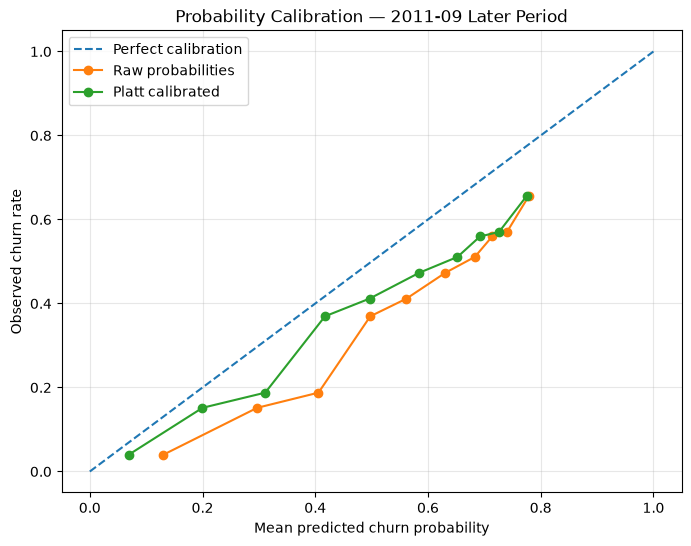

In [10]:
raw_prob_true, raw_prob_pred = calibration_curve(
    y_test,
    test_raw_prob_cal_pipeline,
    n_bins=10,
    strategy="quantile",
)

platt_prob_true, platt_prob_pred = calibration_curve(
    y_test,
    test_platt_prob,
    n_bins=10,
    strategy="quantile",
)


plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

plt.plot(
    raw_prob_pred,
    raw_prob_true,
    marker="o",
    label="Raw probabilities",
)

plt.plot(
    platt_prob_pred,
    platt_prob_true,
    marker="o",
    label="Platt calibrated",
)

plt.xlabel("Mean predicted churn probability")
plt.ylabel("Observed churn rate")
plt.title("Probability Calibration — 2011-09 Later Period")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Reliability Curve — Interpretation

The reliability curve confirms that Platt scaling improves probability calibration on the later 2011-09 period.

The calibrated curve is generally closer to the perfect-calibration diagonal than the raw probability curve, particularly across the lower and middle risk ranges.

However, most points remain below the diagonal. This indicates that even after calibration, predicted churn probabilities are still systematically higher than the observed churn rates within many customer groups.

The visual evidence is consistent with the numerical results:

- Brier score improved from **0.2244 to 0.2120**;
- the mean probability overprediction decreased from approximately **15.08 to 9.93 percentage points**;
- customer ranking remained unchanged.

Platt scaling is therefore retained for downstream probability-based analysis because it provides a meaningful improvement over the raw probabilities, while the remaining temporal calibration error is explicitly acknowledged as a limitation.

### 4.6 Model Explainability

The calibrated churn pipeline is based on the same five-feature Logistic Regression specification selected in Phase 3.

Because the model inputs are standardized, the fitted coefficients can be compared to understand the relative direction and strength of each feature's relationship with predicted churn risk.

For each coefficient:

- a **positive** value means that higher values of the feature increase predicted churn risk;
- a **negative** value means that higher values decrease predicted churn risk;
- a larger absolute coefficient indicates a stronger contribution within the linear model.

For frequency, monetary value, total units, and average order value, interpretation applies to their log-transformed and standardized versions. Recency is standardized without a log transformation.

These coefficients describe model associations rather than causal effects.

In [11]:
coefficient_table = pd.DataFrame(
    {
        "feature": feature_columns,
        "coefficient": calibration_base_model.coef_[0],
    }
)

coefficient_table["absolute_coefficient"] = (
    coefficient_table["coefficient"].abs()
)

coefficient_table["odds_ratio_per_1sd"] = np.exp(
    coefficient_table["coefficient"]
)

coefficient_table = coefficient_table.sort_values(
    "absolute_coefficient",
    ascending=False,
).reset_index(drop=True)

coefficient_table.round(3)

,feature,coefficient,absolute_coefficient,odds_ratio_per_1sd
0,frequency,-1.368,1.368,0.255
1,monetary_value,0.696,0.696,2.005
2,avg_order_value,-0.642,0.642,0.526
3,recency_days,0.128,0.128,1.136
4,total_units,-0.021,0.021,0.979


#### Logistic Regression Coefficients — Initial Interpretation

The strongest coefficient belongs to **purchase frequency**.

- **Frequency:** coefficient = -1.368. Higher purchase frequency is strongly associated with lower predicted churn risk.
- **Average order value:** coefficient = -0.642. Higher average order value is associated with lower predicted churn risk after accounting for the other model variables.
- **Recency:** coefficient = 0.128. Customers who have gone longer without purchasing are associated with higher churn risk.
- **Total units:** coefficient = -0.021, indicating very little additional linear contribution once the other purchasing variables are included.
- **Monetary value:** coefficient = 0.696.

The positive monetary-value coefficient should not be interpreted in isolation as evidence that higher-spending customers are more likely to churn. Frequency, monetary value, total units, and average order value contain overlapping information and are correlated with one another.

Logistic Regression coefficients represent each feature's conditional relationship with the model outcome while the remaining predictors are held constant. Multicollinearity can therefore affect both coefficient magnitude and sign.

A multicollinearity diagnostic is examined before drawing stronger conclusions from individual coefficient values.

#### 4.6.1 Check Multicollinearity

Variance Inflation Factor (VIF) is used to assess how strongly each model feature can be explained by the remaining predictors.

Higher VIF values indicate greater redundancy between features and suggest that individual Logistic Regression coefficients should be interpreted cautiously.

In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


vif_table = pd.DataFrame(
    {
        "feature": feature_columns,
        "VIF": [
            variance_inflation_factor(
                X_train_cal_scaled,
                i,
            )
            for i in range(
                X_train_cal_scaled.shape[1]
            )
        ],
    }
)

vif_table = vif_table.sort_values(
    "VIF",
    ascending=False,
).reset_index(drop=True)

vif_table.round(2)

,feature,VIF
0,monetary_value,201.32
1,avg_order_value,85.72
2,frequency,84.69
3,total_units,6.53
4,recency_days,1.34


#### Multicollinearity — Interpretation

The VIF analysis confirms substantial multicollinearity among several purchasing variables.

- **Monetary value:** VIF = 201.32
- **Average order value:** VIF = 85.72
- **Frequency:** VIF = 84.69
- **Total units:** VIF = 6.53
- **Recency:** VIF = 1.34

The highest VIF values occur among features that capture overlapping aspects of purchasing behavior.

In particular, monetary value, frequency, and average order value are closely related by construction, while total units also reflects purchasing intensity.

This means individual Logistic Regression coefficients should not be interpreted as isolated measures of business importance. Their signs and magnitudes represent conditional effects in the presence of strongly correlated predictors and can therefore be unstable.

The model can still perform well predictively despite multicollinearity, but explanation should focus on broader behavioral patterns rather than treating any single coefficient as an independent causal effect.

Recency has very low multicollinearity and can therefore be interpreted more directly than the overlapping purchasing-value variables.

#### 4.6.2 Held-Out Permutation Importance

Permutation importance measures how much model performance decreases when one feature is randomly shuffled while the remaining variables are left unchanged.

The analysis is performed on the 2011-06 validation period using the base Logistic Regression model that was trained only on the earlier three snapshots.

A larger decrease in ROC-AUC indicates that the model relies more strongly on that feature for customer-risk ranking.

Because correlated predictors can partially substitute for one another, permutation importance should still be interpreted as predictive reliance rather than causal importance.

In [13]:
from sklearn.inspection import permutation_importance


permutation_results = permutation_importance(
    calibration_base_model,
    X_calibration_scaled,
    y_calibration,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42,
    n_jobs=-1,
)


permutation_table = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance_mean": permutation_results.importances_mean,
        "importance_std": permutation_results.importances_std,
    }
)

permutation_table = permutation_table.sort_values(
    "importance_mean",
    ascending=False,
).reset_index(drop=True)

permutation_table.round(4)

,feature,importance_mean,importance_std
0,frequency,0.3172,0.0073
1,avg_order_value,0.0953,0.0062
2,monetary_value,0.0255,0.0043
3,recency_days,0.0048,0.0021
4,total_units,0.0009,0.0003


#### Permutation Importance — Interpretation

Held-out permutation importance shows that **purchase frequency is the model's strongest source of predictive ranking information**.

Mean decreases in validation ROC-AUC after shuffling each feature were:

- **Frequency:** 0.3172
- **Average order value:** 0.0953
- **Monetary value:** 0.0255
- **Recency:** 0.0048
- **Total units:** 0.0009

Frequency therefore contributes substantially more to customer-risk ranking than any other individual feature in the current model.

Average order value provides the second-largest contribution, while monetary value adds a smaller amount of predictive information. Recency and total units provide little additional ranking information after the other variables are included.

This result also helps interpret the earlier coefficient analysis. Although the Logistic Regression coefficients suggested several strong conditional relationships, permutation importance indicates which variables the fitted model actually depends on most for held-out discrimination.

The importance values should still be interpreted cautiously because the purchasing variables are strongly correlated. Correlated features can substitute for one another, and shuffling a single feature can also create combinations that do not naturally occur in the data. The results therefore describe **predictive reliance**, not independent causal importance.

#### 4.6.3 Visualize Held-Out Feature Importance

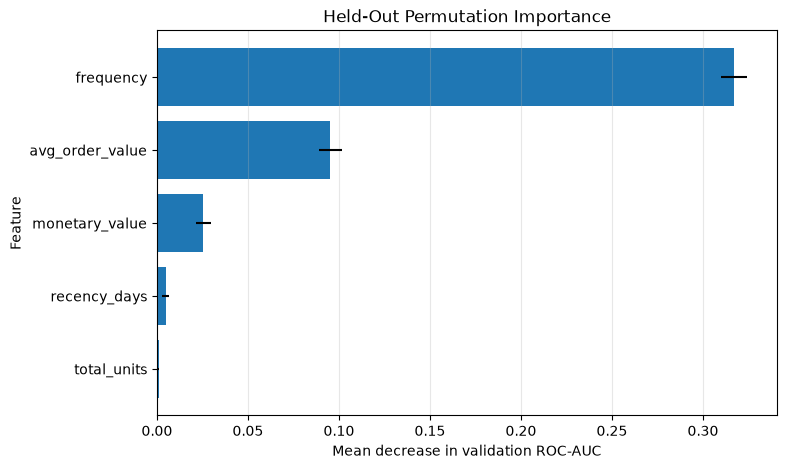

In [14]:
plot_importance = permutation_table.sort_values(
    "importance_mean",
    ascending=True,
)

plt.figure(figsize=(8, 5))

plt.barh(
    plot_importance["feature"],
    plot_importance["importance_mean"],
    xerr=plot_importance["importance_std"],
)

plt.xlabel("Mean decrease in validation ROC-AUC")
plt.ylabel("Feature")
plt.title("Held-Out Permutation Importance")

plt.grid(
    axis="x",
    alpha=0.3,
)

plt.show()

#### Held-Out Feature Importance — Visual Interpretation

The permutation-importance visualization reinforces the numerical results.

Purchase **frequency** is by far the strongest contributor to held-out churn-risk ranking, with a much larger decrease in ROC-AUC when shuffled than any other feature.

Average order value provides the second-largest contribution, followed by monetary value. Recency adds relatively little incremental ranking information once the other customer-behavior variables are present, while total units contributes almost no additional discrimination.

The very small error bars across repeated permutations indicate that this ranking is stable on the validation period.

Because several purchasing variables are strongly correlated, these values should be interpreted as the model's predictive reliance on each feature rather than as independent or causal effects.

### 4.7 SHAP Model Explanations

SHAP is used to explain how individual customer features contribute to the churn-risk score produced by the underlying Logistic Regression model.

The SHAP values describe contributions to the model's **log-odds of churn**, rather than direct percentage-point changes in the final calibrated probability.

The Platt calibration layer changes the probability scale but preserves the ordering and direction of the underlying model score because the fitted calibration relationship is monotonic.

SHAP explanations are therefore used to understand **why the base model assigns higher or lower churn risk**, while calibrated probabilities are reported separately for business interpretation.

In [17]:
shap_explainer = shap.LinearExplainer(
    calibration_base_model,
    X_train_cal_scaled,
    feature_names=feature_columns,
)

test_shap_values = shap_explainer(
    X_test_cal_scaled
)


print(
    "SHAP value matrix shape:",
    test_shap_values.values.shape,
)

print(
    "Number of test customers:",
    len(test_snapshot),
)

print(
    "Base log-odds value:",
    round(
        float(test_shap_values.base_values[0]),
        4,
    ),
)

SHAP value matrix shape: (2768, 5)
Number of test customers: 2768
Base log-odds value: 0.1852


#### 4.7.1 Correlation-Aware SHAP

The churn model contains strongly correlated purchasing variables, particularly frequency, monetary value, and average order value.

Standard feature-independent SHAP explanations can assign attribution unrealistically when correlated predictors contain overlapping information.

A correlation-aware Linear SHAP explainer is therefore used so that explanatory credit can be shared across correlated features.

SHAP values remain descriptive model explanations rather than causal effects.

In [18]:
correlation_masker = shap.maskers.Impute(
    X_train_cal_scaled
)

shap_explainer = shap.LinearExplainer(
    calibration_base_model,
    correlation_masker,
    nsamples=1000,
    feature_names=feature_columns,
)

test_shap_values = shap_explainer(
    X_test_cal_scaled
)


print(
    "Correlation-aware SHAP shape:",
    test_shap_values.values.shape,
)

print(
    "Base log-odds value:",
    round(
        float(test_shap_values.base_values[0]),
        4,
    ),
)

Estimating transforms: 100%|██████████| 1000/1000 [00:00<00:00, 3956.29it/s]


Correlation-aware SHAP shape: (2768, 5)
Base log-odds value: 0.0944


#### 4.7.2 Global Correlation-Aware SHAP Summary

Global SHAP importance is calculated as the mean absolute SHAP value across customers in the later 2011-09 period.

Unlike the earlier coefficient table, these values summarize each feature's contribution to model predictions across individual customers.

The correlation-aware explainer allows attribution to be shared among overlapping purchasing variables, making the results more appropriate for this highly correlated feature set.

The accompanying beeswarm plot also shows the direction of each contribution:

- positive SHAP values push the model toward higher churn risk;
- negative SHAP values push the model toward lower churn risk.

SHAP values describe contributions to the model's log-odds score and should not be interpreted as causal effects.

,feature,mean_absolute_shap
0,frequency,0.3088
1,monetary_value,0.2346
2,total_units,0.2118
3,recency_days,0.1972
4,avg_order_value,0.0576


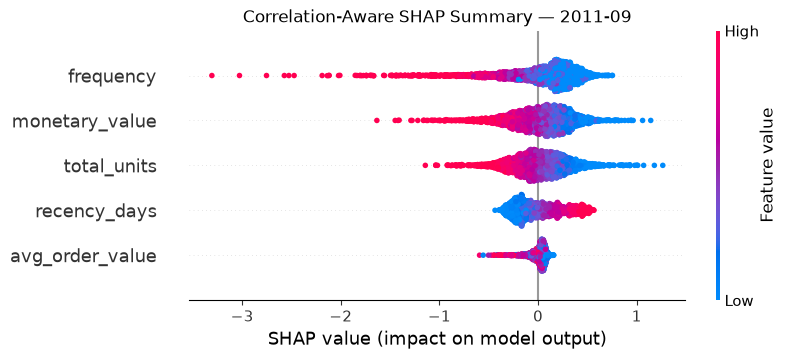

In [19]:
mean_abs_shap = np.abs(
    test_shap_values.values
).mean(axis=0)

shap_importance_table = pd.DataFrame(
    {
        "feature": feature_columns,
        "mean_absolute_shap": mean_abs_shap,
    }
)

shap_importance_table = shap_importance_table.sort_values(
    "mean_absolute_shap",
    ascending=False,
).reset_index(drop=True)

display(
    shap_importance_table.round(4)
)


shap.plots.beeswarm(
    test_shap_values,
    max_display=5,
    show=False,
)

plt.title(
    "Correlation-Aware SHAP Summary — 2011-09"
)

plt.show()

#### Correlation-Aware SHAP — Interpretation

The correlation-aware SHAP analysis provides a more nuanced explanation of the churn model than the raw Logistic Regression coefficients.

Mean absolute SHAP values rank the features as:

- **Frequency:** 0.3088
- **Monetary value:** 0.2346
- **Total units:** 0.2118
- **Recency:** 0.1972
- **Average order value:** 0.0576

Purchase frequency remains the strongest overall contributor to model predictions, consistent with the permutation-importance analysis.

The SHAP beeswarm also reveals the direction of the model's associations:

- **higher purchase frequency** generally pushes predicted churn risk downward;
- **higher monetary value** generally pushes churn risk downward;
- **higher total purchase volume** generally pushes churn risk downward;
- **longer recency** generally pushes churn risk upward;
- **average order value** has a comparatively small contribution after correlated purchasing behavior is taken into account.

This is especially important for interpreting monetary value. Its raw Logistic Regression coefficient was positive, but the model also contains strongly correlated purchasing variables. Once SHAP distributes attribution across this correlated feature structure, higher customer spending is generally associated with lower modeled churn risk.

The difference between permutation importance and SHAP feature rankings is expected. Permutation importance measures the loss of held-out ranking performance when a variable is disrupted, whereas SHAP distributes individual prediction contributions across correlated predictors.

Together, the analyses suggest that **overall purchasing engagement—especially frequency—is the dominant behavioral signal**, while prolonged inactivity increases churn risk.

These explanations describe how the fitted model behaves and should not be interpreted as causal effects.

### 4.8 Customer-Level Churn Explanations

Global importance describes the model overall, but retention decisions are made at the customer level.

The later-period customer records are therefore combined with:

- original behavioral feature values;
- raw model probability;
- Platt-calibrated churn probability;
- observed churn outcome.

Representative customers can then be examined with SHAP to understand which behaviors push their individual risk estimates upward or downward.

In [20]:
customer_risk = test_snapshot[
    [
        "customer_id",
        "recency_days",
        "frequency",
        "monetary_value",
        "total_units",
        "avg_order_value",
        "churn",
    ]
].copy()


customer_risk["raw_churn_probability"] = (
    test_raw_prob_cal_pipeline
)

customer_risk["calibrated_churn_probability"] = (
    test_platt_prob
)


customer_risk = customer_risk.sort_values(
    "calibrated_churn_probability",
    ascending=False,
).reset_index()


customer_risk[
    [
        "customer_id",
        "recency_days",
        "frequency",
        "monetary_value",
        "total_units",
        "avg_order_value",
        "raw_churn_probability",
        "calibrated_churn_probability",
        "churn",
    ]
].head(10).round(3)

,customer_id,recency_days,frequency,monetary_value,total_units,avg_order_value,raw_churn_probability,calibrated_churn_probability,churn
0,17816,170,1,5.10,6,5.10,0.888,0.904,0
1,16446,106,1,2.90,2,2.90,0.884,0.900,1
2,17956,150,1,12.75,1,12.75,0.864,0.877,1
3,14285,77,1,5.90,2,5.90,0.861,0.874,0
4,17763,164,1,15.00,12,15.00,0.860,0.873,1
5,15863,93,1,9.20,2,9.20,0.854,0.866,0
6,17102,162,1,25.50,2,25.50,0.847,0.858,1
7,13573,154,1,31.77,10,31.77,0.834,0.843,0
8,16162,153,1,37.40,4,37.40,0.830,0.838,1
9,13120,139,1,30.60,12,30.60,0.830,0.838,1


#### 4.8.1 Explain a High-Risk Customer

A representative high-risk customer is selected to illustrate how individual behavioral features combine to produce the model's churn-risk score.

Customer **16446** had:

- recency = 106 days;
- frequency = 1 order;
- monetary value = £2.90;
- total units = 2;
- average order value = £2.90;
- calibrated churn probability = 90.0%;
- observed outcome = churn.

The SHAP waterfall plot decomposes this customer's underlying model score into feature-level contributions.

Positive SHAP values push the prediction toward higher churn risk, while negative values push it toward lower risk.

Customer: 16446
Raw churn probability: 88.43%
Calibrated churn probability: 90.01%
Observed churn: 1


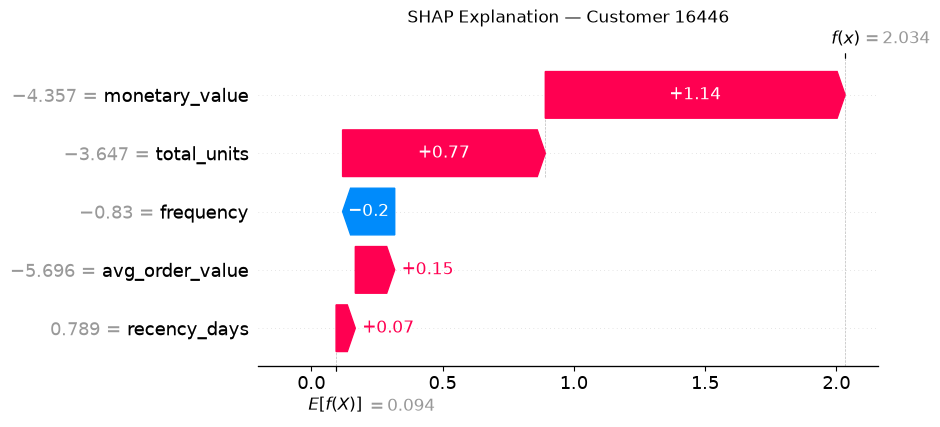

In [21]:
chosen_customer_id = 16446

chosen_row = customer_risk.loc[
    customer_risk["customer_id"] == chosen_customer_id
].iloc[0]

original_test_index = int(
    chosen_row["index"]
)

print(
    "Customer:",
    chosen_customer_id
)

print(
    "Raw churn probability:",
    f"{chosen_row['raw_churn_probability']:.2%}"
)

print(
    "Calibrated churn probability:",
    f"{chosen_row['calibrated_churn_probability']:.2%}"
)

print(
    "Observed churn:",
    int(chosen_row["churn"])
)


shap.plots.waterfall(
    test_shap_values[original_test_index],
    max_display=5,
    show=False,
)

plt.title(
    f"SHAP Explanation — Customer {chosen_customer_id}"
)

plt.show()

#### High-Risk Customer — Interpretation

Customer **16446** received a very high calibrated churn probability of **90.01%** and subsequently churned.

The customer's observed behavior before the cutoff was:

- **106 days since the last purchase**;
- only **1 purchase** during the observation window;
- only **£2.90 in merchandise spending**;
- only **2 units purchased**;
- **£2.90 average order value**.

The SHAP explanation shows that the strongest upward contributions to the model's churn-risk score came from the customer's extremely low **monetary value** and **purchase volume**.

Longer inactivity also pushed the prediction toward higher churn risk.

The contribution assigned to frequency is slightly negative for this individual customer. This should not be interpreted as evidence that low frequency generally reduces churn risk. The model contains strongly correlated purchasing variables, and the correlation-aware SHAP method distributes explanatory credit across those overlapping signals.

Globally, frequency remains the strongest predictive feature, while this local explanation shows how the model combines several aspects of weak purchasing engagement for one customer.

The numerical feature values displayed on the SHAP waterfall are the transformed and standardized values used by the model, rather than the customer's original business-scale values. The raw values above are therefore used for business interpretation.

As with all SHAP explanations, these contributions explain the fitted model's prediction and do not establish causal drivers of churn.

### 4.9 Revenue at Risk

Churn probability alone identifies customers who are most likely to become inactive, but it does not account for the financial importance of each customer.

A high-risk low-value customer may represent less financial exposure than a moderately high-risk customer with substantial historical spending.

Because the dataset does not reveal the counterfactual revenue a customer would have generated if they had remained active, future customer value cannot be observed directly.

A simple historical spending-rate proxy is therefore used.

For each customer:

- historical merchandise revenue is measured over the 180-day observation window;
- this value is scaled to a 90-day horizon by multiplying by 0.5;
- the resulting 90-day value proxy is multiplied by the customer's Platt-calibrated churn probability.

The resulting metric is:

**Estimated 90-day revenue at risk = calibrated churn probability × 90-day historical revenue proxy**

This should be interpreted as a **financial-prioritization estimate**, not as a causal or guaranteed revenue-loss forecast.

The estimate also inherits the remaining calibration error identified earlier in Phase 4.

In [22]:
customer_risk["monetary_value"] = pd.to_numeric(
    customer_risk["monetary_value"]
)


# Scale the 180-day historical revenue to the 90-day churn horizon.
customer_risk["projected_90d_value_proxy"] = (
    customer_risk["monetary_value"] * 0.5
)


# Probability-weighted financial exposure.
customer_risk["revenue_at_risk_90d"] = (
    customer_risk["projected_90d_value_proxy"]
    * customer_risk["calibrated_churn_probability"]
)


revenue_risk_ranking = customer_risk.sort_values(
    "revenue_at_risk_90d",
    ascending=False,
).reset_index(drop=True)


total_90d_value_proxy = (
    customer_risk["projected_90d_value_proxy"].sum()
)

total_revenue_at_risk = (
    customer_risk["revenue_at_risk_90d"].sum()
)


print(
    "Total 90-day historical value proxy:",
    f"£{total_90d_value_proxy:,.2f}",
)

print(
    "Probability-weighted revenue at risk:",
    f"£{total_revenue_at_risk:,.2f}",
)

print(
    "Revenue-at-risk share of value proxy:",
    f"{total_revenue_at_risk / total_90d_value_proxy:.2%}",
)


revenue_risk_ranking[
    [
        "customer_id",
        "recency_days",
        "frequency",
        "monetary_value",
        "calibrated_churn_probability",
        "projected_90d_value_proxy",
        "revenue_at_risk_90d",
        "churn",
    ]
].head(10).round(2)

Total 90-day historical value proxy: £1,743,419.59
Probability-weighted revenue at risk: £371,526.51
Revenue-at-risk share of value proxy: 21.31%


,customer_id,recency_days,frequency,monetary_value,calibrated_churn_probability,projected_90d_value_proxy,revenue_at_risk_90d,churn
0,15749,136,1,21535.90,0.39,10767.95,4156.86,1
1,15098,83,3,39916.50,0.16,19958.25,3106.10,1
2,12590,112,1,9341.26,0.43,4670.63,2019.46,1
3,12409,83,1,6207.08,0.44,3103.54,1371.70,0
4,12435,168,1,3978.99,0.55,1989.50,1089.57,0
5,13081,44,3,11402.51,0.18,5701.26,1022.06,0
6,12753,36,2,7279.78,0.28,3639.89,1020.49,0
7,12688,14,1,4873.81,0.41,2436.91,992.99,1
8,12744,45,2,6068.06,0.30,3034.03,903.21,0
9,12378,30,1,4008.62,0.43,2004.31,871.55,1


#### Revenue-at-Risk — Interpretation

Across the 2011-09 customer population:

- the 90-day historical value proxy totals **£1,743,419.59**;
- probability-weighted estimated revenue at risk totals **£371,526.51**;
- this represents approximately **21.31%** of the total 90-day value proxy.

The ranking differs substantially from a ranking based only on churn probability.

For example, customer **15749** has a calibrated churn probability of approximately **39%**, which is far below the highest-risk customers identified earlier. However, the customer's high historical spending produces the largest estimated 90-day financial exposure at approximately **£4,156.86**.

This demonstrates why churn probability alone is insufficient for retention prioritization. The customers most likely to churn are not necessarily the customers associated with the greatest potential financial exposure.

Revenue at risk combines both dimensions:

- **likelihood of churn**;
- **historical customer value**.

The resulting metric is intended for relative retention prioritization rather than as a guaranteed forecast of future revenue loss.

#### 4.9.1 Churn Risk vs Financial Risk

Two retention-targeting strategies are compared:

1. targeting customers with the highest calibrated churn probabilities;
2. targeting customers with the highest estimated revenue at risk.

Comparing the two rankings shows whether probability-only targeting would overlook financially important customers.

In [23]:
top_n = 20


top_churn_risk = customer_risk.nlargest(
    top_n,
    "calibrated_churn_probability",
).copy()

top_financial_risk = customer_risk.nlargest(
    top_n,
    "revenue_at_risk_90d",
).copy()


churn_risk_ids = set(
    top_churn_risk["customer_id"]
)

financial_risk_ids = set(
    top_financial_risk["customer_id"]
)

overlap_ids = (
    churn_risk_ids
    & financial_risk_ids
)


print(
    "Top customers compared:",
    top_n,
)

print(
    "Customers appearing in both rankings:",
    len(overlap_ids),
)

print(
    "Ranking overlap:",
    f"{len(overlap_ids) / top_n:.1%}",
)


comparison_summary = pd.DataFrame(
    {
        "strategy": [
            "Highest churn probability",
            "Highest revenue at risk",
        ],
        "mean_churn_probability": [
            top_churn_risk[
                "calibrated_churn_probability"
            ].mean(),
            top_financial_risk[
                "calibrated_churn_probability"
            ].mean(),
        ],
        "total_90d_value_proxy": [
            top_churn_risk[
                "projected_90d_value_proxy"
            ].sum(),
            top_financial_risk[
                "projected_90d_value_proxy"
            ].sum(),
        ],
        "total_revenue_at_risk": [
            top_churn_risk[
                "revenue_at_risk_90d"
            ].sum(),
            top_financial_risk[
                "revenue_at_risk_90d"
            ].sum(),
        ],
        "observed_churn_rate": [
            top_churn_risk["churn"].mean(),
            top_financial_risk["churn"].mean(),
        ],
    }
)

comparison_summary

Top customers compared: 20
Customers appearing in both rankings: 0
Ranking overlap: 0.0%


,strategy,mean_churn_probability,total_90d_value_proxy,total_revenue_at_risk,observed_churn_rate
0,Highest churn probability,0.847654,249.62,208.890069,0.55
1,Highest revenue at risk,0.354020,106710.44,24028.997589,0.30


#### Churn-Risk vs Financial-Risk Targeting — Interpretation

The top-20 churn-probability and revenue-at-risk rankings have **no customers in common**.

This demonstrates a substantial difference between identifying customers who are most likely to churn and identifying customers whose churn represents the greatest estimated financial exposure.

The top 20 customers by churn probability have:

- mean calibrated churn probability = **84.77%**;
- total 90-day value proxy = **£249.62**;
- estimated revenue at risk = **£208.89**;
- observed churn rate = **55%**.

In contrast, the top 20 customers by revenue at risk have:

- mean calibrated churn probability = **35.40%**;
- total 90-day value proxy = **£106,710.44**;
- estimated revenue at risk = **£24,029.00**;
- observed churn rate = **30%**.

Probability-only targeting therefore concentrates on customers with very high modeled churn likelihood but very little historical financial value.

Revenue-at-risk targeting accepts lower average churn probability in exchange for substantially greater financial exposure.

The lower observed churn rate in the financial-risk group should not be interpreted as weaker targeting performance because the objective is different. The financial-risk strategy is designed to prioritize expected monetary exposure rather than maximize the number of churners identified.

#### 4.9.2 Financial Exposure Captured by Each Top-20 Strategy

The financial exposure captured by the two top-20 targeting strategies is compared directly.

In [24]:
churn_target_risk = top_churn_risk[
    "revenue_at_risk_90d"
].sum()

financial_target_risk = top_financial_risk[
    "revenue_at_risk_90d"
].sum()


relative_capture = (
    churn_target_risk
    / financial_target_risk
)

relative_shortfall = (
    1 - relative_capture
)


print(
    "Revenue at risk captured by churn-probability targeting:",
    f"£{churn_target_risk:,.2f}",
)

print(
    "Revenue at risk captured by financial-risk targeting:",
    f"£{financial_target_risk:,.2f}",
)

print(
    "Probability-only strategy captures:",
    f"{relative_capture:.2%}",
    "of the financial exposure captured by the revenue-at-risk strategy.",
)

print(
    "Relative financial-exposure shortfall:",
    f"{relative_shortfall:.2%}",
)

Revenue at risk captured by churn-probability targeting: £208.89
Revenue at risk captured by financial-risk targeting: £24,029.00
Probability-only strategy captures: 0.87% of the financial exposure captured by the revenue-at-risk strategy.
Relative financial-exposure shortfall: 99.13%


#### Financial Exposure Capture — Interpretation

The difference between probability-only and value-aware targeting is substantial.

Among the top 20 selected customers:

- churn-probability targeting captures **£208.89** of estimated revenue at risk;
- revenue-at-risk targeting captures **£24,029.00**;
- the probability-only strategy captures only **0.87%** as much financial exposure;
- this corresponds to a **99.13% relative shortfall** compared with directly ranking customers by estimated revenue at risk.

This result illustrates that optimizing solely for churn likelihood can produce a retention list dominated by very high-risk but extremely low-value customers.

When the business objective is to prioritize financial exposure, combining customer value with calibrated churn probability produces a fundamentally different targeting strategy.

The comparison is specific to the top-20 targeting capacity and to the historical-value proxy used in this analysis. It should therefore be interpreted as a prioritization result rather than as an estimate of guaranteed recoverable revenue.

#### 4.9.3 Financial Targeting Across Contact Budgets

The two targeting strategies are now compared across realistic campaign capacities.

For each contact budget, customers are ranked either by:

- calibrated churn probability; or
- estimated 90-day revenue at risk.

The comparison measures how much of the population's total estimated financial exposure is captured by each strategy.

In [25]:
financial_budgets = [0.05, 0.10, 0.20]

financial_budget_results = []

total_population_risk = customer_risk[
    "revenue_at_risk_90d"
].sum()


for budget in financial_budgets:
    n_contact = int(
        np.ceil(
            len(customer_risk) * budget
        )
    )

    churn_selected = customer_risk.nlargest(
        n_contact,
        "calibrated_churn_probability",
    )

    financial_selected = customer_risk.nlargest(
        n_contact,
        "revenue_at_risk_90d",
    )

    for strategy, selected in [
        (
            "Highest churn probability",
            churn_selected,
        ),
        (
            "Highest revenue at risk",
            financial_selected,
        ),
    ]:
        captured_risk = selected[
            "revenue_at_risk_90d"
        ].sum()

        financial_budget_results.append(
            {
                "strategy": strategy,
                "contact_budget": f"{int(budget * 100)}%",
                "customers_contacted": n_contact,
                "mean_churn_probability": selected[
                    "calibrated_churn_probability"
                ].mean(),
                "captured_revenue_at_risk": captured_risk,
                "share_of_total_revenue_at_risk": (
                    captured_risk
                    / total_population_risk
                ),
                "observed_churn_rate": selected[
                    "churn"
                ].mean(),
            }
        )


financial_budget_table = pd.DataFrame(
    financial_budget_results
)

financial_budget_table[
    [
        "mean_churn_probability",
        "share_of_total_revenue_at_risk",
        "observed_churn_rate",
    ]
] = financial_budget_table[
    [
        "mean_churn_probability",
        "share_of_total_revenue_at_risk",
        "observed_churn_rate",
    ]
].round(4)

financial_budget_table[
    "captured_revenue_at_risk"
] = financial_budget_table[
    "captured_revenue_at_risk"
].round(2)

financial_budget_table

,strategy,contact_budget,customers_contacted,mean_churn_probability,captured_revenue_at_risk,share_of_total_revenue_at_risk,observed_churn_rate
0,Highest churn probability,5%,139,0.7957,4693.36,0.0126,0.6547
1,Highest revenue at risk,5%,139,0.4133,71402.12,0.1922,0.3813
2,Highest churn probability,10%,277,0.7757,12395.35,0.0334,0.6570
3,Highest revenue at risk,10%,277,0.4099,107919.57,0.2905,0.3249
4,Highest churn probability,20%,554,0.7509,33785.65,0.0909,0.6137
5,Highest revenue at risk,20%,554,0.4051,163517.42,0.4401,0.3051


#### Financial Targeting Across Budgets — Interpretation

The targeting trade-off remains consistent across 5%, 10%, and 20% campaign capacities.

At a **5% contact budget**:

- churn-probability targeting captures **1.26%** of total estimated revenue at risk;
- revenue-at-risk targeting captures **19.22%**;
- observed churn rates are **65.47%** and **38.13%**, respectively.

At a **10% contact budget**:

- churn-probability targeting captures **3.34%** of total estimated revenue at risk;
- revenue-at-risk targeting captures **29.05%**;
- observed churn rates are **65.70%** and **32.49%**, respectively.

At a **20% contact budget**:

- churn-probability targeting captures **9.09%** of total estimated revenue at risk;
- revenue-at-risk targeting captures **44.01%**;
- observed churn rates are **61.37%** and **30.51%**, respectively.

These results illustrate two different retention objectives.

**Churn-probability targeting** is better suited to campaigns whose main objective is to identify as many likely churners as possible.

**Revenue-at-risk targeting** is better suited to campaigns whose objective is to protect the greatest amount of expected financial value under a limited contact budget.

Across every evaluated budget, the value-aware strategy captures substantially more estimated financial exposure despite targeting customers with lower average churn probabilities.

The preferred strategy should therefore depend on the business objective rather than on churn probability alone.

#### 4.9.4 Financial Targeting Uplift

The financial advantage of value-aware targeting is summarized by comparing the estimated revenue at risk captured by the two strategies at each contact budget.

In [26]:
financial_uplift_rows = []

for budget in ["5%", "10%", "20%"]:
    budget_rows = financial_budget_table[
        financial_budget_table["contact_budget"] == budget
    ]

    churn_capture = budget_rows.loc[
        budget_rows["strategy"] == "Highest churn probability",
        "captured_revenue_at_risk",
    ].iloc[0]

    financial_capture = budget_rows.loc[
        budget_rows["strategy"] == "Highest revenue at risk",
        "captured_revenue_at_risk",
    ].iloc[0]

    financial_uplift_rows.append(
        {
            "contact_budget": budget,
            "churn_probability_targeting": churn_capture,
            "revenue_at_risk_targeting": financial_capture,
            "financial_capture_multiplier": (
                financial_capture / churn_capture
            ),
        }
    )


financial_uplift_table = pd.DataFrame(
    financial_uplift_rows
)

financial_uplift_table[
    [
        "churn_probability_targeting",
        "revenue_at_risk_targeting",
        "financial_capture_multiplier",
    ]
] = financial_uplift_table[
    [
        "churn_probability_targeting",
        "revenue_at_risk_targeting",
        "financial_capture_multiplier",
    ]
].round(2)

financial_uplift_table

,contact_budget,churn_probability_targeting,revenue_at_risk_targeting,financial_capture_multiplier
0,5%,4693.36,71402.12,15.21
1,10%,12395.35,107919.57,8.71
2,20%,33785.65,163517.42,4.84


#### Financial Targeting Uplift — Interpretation

Value-aware targeting produces a substantial increase in captured financial exposure at every evaluated campaign capacity.

Compared with ranking customers only by churn probability, revenue-at-risk targeting captures:

- **15.21× more estimated financial exposure at a 5% contact budget**;
- **8.71× more at a 10% contact budget**;
- **4.84× more at a 20% contact budget**.

The financial advantage is greatest when campaign capacity is most constrained.

As the contact budget expands, the difference between the two strategies naturally narrows because both approaches begin to include a broader portion of the customer population.

However, even at a 20% contact budget, value-aware targeting captures nearly five times as much estimated financial exposure.

This reinforces the practical distinction between predicting churn and prioritizing retention actions: the highest-probability customers are not necessarily the customers whose loss presents the greatest financial risk.

#### 4.9.5 Financial Exposure Capture by Contact Budget

The following chart compares the share of total estimated revenue at risk captured by each targeting strategy as campaign capacity increases.

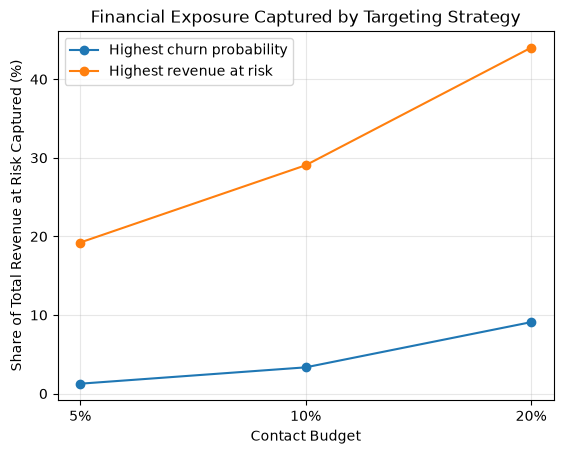

In [27]:
capture_plot = (
    financial_budget_table[
        [
            "strategy",
            "contact_budget",
            "share_of_total_revenue_at_risk",
        ]
    ]
    .copy()
)


budget_order = ["5%", "10%", "20%"]

capture_plot["contact_budget"] = pd.Categorical(
    capture_plot["contact_budget"],
    categories=budget_order,
    ordered=True,
)

capture_plot = capture_plot.sort_values(
    "contact_budget"
)


for strategy in capture_plot["strategy"].unique():
    strategy_data = capture_plot[
        capture_plot["strategy"] == strategy
    ]

    plt.plot(
        strategy_data["contact_budget"],
        strategy_data["share_of_total_revenue_at_risk"] * 100,
        marker="o",
        label=strategy,
    )


plt.xlabel("Contact Budget")
plt.ylabel("Share of Total Revenue at Risk Captured (%)")
plt.title(
    "Financial Exposure Captured by Targeting Strategy"
)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Financial Exposure Capture — Visual Interpretation

The targeting curves show a consistent advantage for revenue-at-risk prioritization across all evaluated contact budgets.

At a 5% campaign capacity, value-aware targeting already captures approximately **19% of total estimated financial exposure**, compared with only about **1%** when customers are ranked solely by churn probability.

The gap remains substantial as campaign capacity increases:

- at 10%, revenue-at-risk targeting captures about **29%**, versus **3%** for probability-only targeting;
- at 20%, it captures about **44%**, versus approximately **9%**.

The chart also shows that the relative advantage is greatest when retention resources are most constrained.

This supports using churn probability as one component of a retention decision rather than as the sole targeting criterion.

### 4.10 Phase 4 Limitations

Several limitations should be considered when interpreting the explainability, calibration, and revenue-at-risk results.

- **Churn is operationally defined as 90 days without a qualifying merchandise purchase.** It represents observed inactivity over the defined horizon rather than permanent customer loss.

- **Calibration remains imperfect over time.** Platt scaling improved the later-period Brier score from 0.2244 to 0.2120 and reduced systematic probability overestimation, but calibrated probabilities still exceeded the observed churn rate on average.

- **The calibration mapping was fitted using the 2011-06 validation period.** Its close fit on that period is therefore in-sample for the calibration layer. The 2011-09 period provides a later-period assessment of the frozen calibrated pipeline.

- **The 2011-09 period had already been inspected during Phase 3.** Phase 4 therefore treats it as a later-period evaluation period rather than claiming it as a newly untouched test set.

- **The calibrated pipeline uses the base Logistic Regression model trained on the first three development snapshots.** The 2011-06 snapshot is reserved for calibration, so this pipeline uses less classifier-training data than the final Phase 3 refit model.

- **The behavioral predictors are strongly correlated.** Frequency, monetary value, total units, and average order value contain overlapping information. Individual Logistic Regression coefficients should therefore not be interpreted as isolated business effects.

- **SHAP explanations describe model behavior rather than causal relationships.** Correlation-aware SHAP reduces some attribution problems caused by correlated predictors, but feature attribution can still depend on the model and explainer assumptions.

- **Revenue at risk is a financial-prioritization proxy, not a forecast of guaranteed lost revenue.** The calculation extrapolates a customer's historical 180-day merchandise spending rate to a 90-day horizon and weights that value by calibrated churn probability.

- **The revenue-at-risk estimate does not model treatment effects.** It does not estimate whether a retention campaign would successfully prevent churn, how much revenue would actually be recovered, or the cost of contacting or incentivizing a customer.

- **Returns, cancellations, and non-merchandise transaction codes are excluded from the modeling table.** Revenue and customer-value measures therefore reflect positive qualifying merchandise purchases only.

These limitations mean the Phase 4 outputs are best used for **risk ranking, explanation, and retention prioritization**, rather than as causal estimates or precise forecasts of recoverable revenue.

### 4.11 Phase 4 Summary

Phase 4 extended the churn model from a customer-ranking system into a more interpretable and financially actionable retention framework.

#### Probability Calibration

The original Phase 3 Logistic Regression model ranked customers reasonably well, but its raw probabilities were systematically too high in the later 2011-09 period.

For the chronological calibration pipeline:

- observed churn rate = **39.31%**;
- mean raw predicted probability = **54.39%**;
- mean Platt-calibrated probability = **49.24%**;
- raw Brier score = **0.2244**;
- calibrated Brier score = **0.2120**;
- PR-AUC remained approximately **0.585**;
- ROC-AUC remained approximately **0.731**.

Platt scaling therefore improved probability accuracy while preserving the model's ranking ability.

Residual overprediction remained, indicating temporal calibration drift and reinforcing that calibrated probabilities should still be treated as estimates rather than exact event frequencies.

#### Model Explainability

Multiple complementary explanation methods were used.

The standardized Logistic Regression coefficients initially suggested strong effects from frequency, monetary value, and average order value. However, Variance Inflation Factor analysis revealed severe multicollinearity:

- monetary value VIF ≈ **201**;
- average order value VIF ≈ **86**;
- frequency VIF ≈ **85**.

Individual coefficients were therefore not interpreted as independent business effects.

Held-out permutation importance showed that **purchase frequency was the dominant predictive feature**, followed by average order value and monetary value.

Correlation-aware SHAP provided a more suitable explanation of the model under correlated customer behavior. Mean absolute SHAP importance ranked:

1. **Frequency — 0.3088**
2. **Monetary value — 0.2346**
3. **Total units — 0.2118**
4. **Recency — 0.1972**
5. **Average order value — 0.0576**

The global SHAP patterns indicated that stronger purchasing engagement generally pushed modeled churn risk downward, while longer periods since the last purchase pushed risk upward.

A customer-level SHAP example demonstrated how these behavioral signals combine to produce an individual risk score.

#### Revenue at Risk

To move beyond churn probability alone, calibrated churn risk was combined with a simple customer-value proxy.

Historical merchandise revenue from the 180-day observation period was scaled to the 90-day churn horizon, and probability-weighted financial exposure was calculated as:

**Estimated 90-day revenue at risk = calibrated churn probability × 90-day historical value proxy**

Across the 2011-09 customer population:

- total 90-day historical value proxy = **£1,743,419.59**;
- estimated probability-weighted revenue at risk = **£371,526.51**;
- estimated revenue at risk represented **21.31%** of the total value proxy.

The analysis showed that customers with the highest churn probability were not necessarily the customers representing the greatest financial exposure.

Among the top 20 customers, there was **0% overlap** between the highest-churn-probability ranking and the highest-revenue-at-risk ranking.

The top-20 probability-only strategy captured only **£208.89** of estimated financial exposure, compared with **£24,029.00** for revenue-at-risk targeting.

#### Contact-Budget Analysis

The advantage of value-aware targeting remained consistent across larger campaign capacities.

Compared with churn-probability targeting, revenue-at-risk targeting captured:

- **15.21× more financial exposure at a 5% contact budget**;
- **8.71× more at a 10% contact budget**;
- **4.84× more at a 20% contact budget**.

At those same budgets, revenue-at-risk targeting captured approximately:

- **19.22%** of total estimated financial exposure at 5%;
- **29.05%** at 10%;
- **44.01%** at 20%.

Probability-only targeting captured approximately:

- **1.26%** at 5%;
- **3.34%** at 10%;
- **9.09%** at 20%.

This demonstrates an important distinction between **predicting who is most likely to churn** and **deciding which customers are most financially important to retain**.

#### Business Conclusion

Phase 4 converts the churn model into a more useful retention decision-support system.

Rather than relying solely on churn probability, the analysis now provides:

- calibrated risk estimates;
- global and customer-level model explanations;
- financially weighted customer prioritization;
- targeting comparisons under constrained campaign budgets.

The results suggest that retention strategy should be aligned with the business objective.

If the goal is to identify the greatest number of likely churners, probability-based targeting is appropriate.

If the goal is to protect the greatest amount of customer value under limited retention capacity, **revenue-at-risk targeting provides substantially stronger financial prioritization**.

These outputs remain predictive and descriptive rather than causal. Actual retention decisions should additionally consider intervention cost, expected treatment effectiveness, customer margin, and experimentally measured campaign uplift.